In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

icu = pd.read_csv("/content/drive/MyDrive/419 AI Health/MIMIC_III/Resources/A_ICU_Info.csv")
icu['INTIME'] = pd.to_datetime(icu['INTIME'])
icu['OUTTIME'] = pd.to_datetime(icu['OUTTIME'])

# Generate Time Intervals
- Rerun this notebook with different `interval_constant` to generate compononents for 6h & 2h intervals

In [ ]:
interval_constant = 6
# interval_constant = 2

In [ ]:
from datetime import timedelta

# Generate time intervals for each admission
def generate_time_intervals(row):
    time_intervals = []
    current_time = row['INTIME']
    # Start at admited time, Interval = 6h
    while current_time < row['OUTTIME']:
        time_intervals.append(current_time)
        current_time += timedelta(hours=interval_constant)

    # The last entry is always OUTTIME
    if time_intervals[-1] != row['OUTTIME']:
        time_intervals.append(row['OUTTIME'])
    return pd.DataFrame({
        'SUBJECT_ID': row['SUBJECT_ID'],
        'ICUSTAY_ID': row['ICUSTAY_ID'],
        'TIME': time_intervals
    })

# Generate time interval for each admission
rows = pd.concat(icu.apply(generate_time_intervals, axis=1).tolist(), ignore_index=True)
df = rows.copy()
df

,SUBJECT_ID,ICUSTAY_ID,TIME
0,268,280836,2198-02-14 23:27:38
1,268,280836,2198-02-15 05:27:38
2,268,280836,2198-02-15 11:27:38
3,268,280836,2198-02-15 17:27:38
4,268,280836,2198-02-15 23:27:38
...,...,...,...
363729,94956,275346,2157-05-22 20:54:54
363730,94956,275346,2157-05-23 02:54:54
363731,94956,275346,2157-05-23 08:54:54
363732,94956,275346,2157-05-23 14:54:54


# Summary of Features and Tables

**Variables used in SOFA:** All time-series
-  GCS, MAP, FiO2, Ventilation status (FROM `CHARTEVENTS`)
- Creatinine, Bilirubin, FiO2, PaO2, Platelets (FROM `LABEVENTS`)
- Dobutamine, Epinephrine, Norepinephrine (FROM `INPUTEVENTS_MV` and `INPUTEVENTS_CV`)
- Urine output (From `OUTPUTEVENTS`)


**Variables used in OASIS:** No lab measurement and some components are static
- Heart rate, GCS, MAP, Temperature, Respiratory rate, Ventilation status (FROM `CHARTEVENTS`)
- Urine output (From `OUTPUTEVENTS`)
- Elective surgery, Pre-ICU in-hospital length of stay, Age(FROM `ICU_general`: column `ADMISSION_TYPE`, `ADMITTIME`-`INTIME`, `AGE`): Static data

**Other candidates for input features:** All time-series
- Vital signs: Oxygen Saturation (spo2), Systolic pressure (sbp), Diastolic pressure (dbp)
- TBD

# CHARTEVENTS

## 1) Load Table

In [ ]:
read_chart = ['ICUSTAY_ID', 'ITEMID', 'CHARTTIME', 'VALUE', 'VALUENUM']

#chart = pd.read_csv('/content/drive/MyDrive/419 AI Health/MIMIC_III/Data/CHARTEVENTS.csv', usecols = read_chart)
## Only Chartevents of ICU patients
#chart = chart[chart['ICUSTAY_ID'].isin(icu['ICUSTAY_ID'])]
## Save the smaller dataset: easy import next time
#chart.to_csv("/content/drive/MyDrive/419 AI Health/MIMIC_III/Resources/A_CHARTEVENTS.csv", index=False)


# If run again, can simply import filtered_CHARTEVENTS.csv
chart = pd.read_csv('/content/drive/MyDrive/419 AI Health/MIMIC_III/Resources/A_CHARTEVENTS.csv', usecols = read_chart)
chart['CHARTTIME'] = pd.to_datetime(chart['CHARTTIME'])

print(chart.shape)
chart.head()

<ipython-input-5-cc2736f64e71>:5: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  chart = pd.read_csv('/content/drive/MyDrive/419 AI Health/MIMIC_III/filtered_CHARTEVENTS.csv', usecols = read_chart)


(89253006, 5)


,ICUSTAY_ID,ITEMID,CHARTTIME,VALUE,VALUENUM
0,241249.0,223834,2134-05-12 12:00:00,15.0,15.00
1,241249.0,223835,2134-05-12 12:00:00,100.0,100.00
2,241249.0,224328,2134-05-12 12:00:00,0.37,0.37
3,241249.0,224329,2134-05-12 12:00:00,6.0,6.00
4,241249.0,224330,2134-05-12 12:00:00,2.5,2.50


In [ ]:
print("Num of ICU stay in icu general:", icu.shape[0])
print("Num of overlapped ICU stay in chart event:", chart['ICUSTAY_ID'].nunique())

## Given the above number, some ICU admissions still do not have any chartevent data, further filter
icu = icu[icu['ICUSTAY_ID'].isin(chart['ICUSTAY_ID'])]
# Also filter df
df = df[df['ICUSTAY_ID'].isin(icu['ICUSTAY_ID'])]

Num of ICU stay in icu general: 33998
Num of overlapped ICU stay in chart event: 33867


##2) Retrieve Component Data
Dataset includes two medical systems CAREVUE and METAVISION, so a single component may have multiple IDs representing 2 systems



#### **GCS** Item ID
- (verbal, motor, eyes): CV (723, 454, 184), MV (223900, 223901, 220739)
- Frequency: 01:10:04.260199097

In [ ]:
gcs_id = [723, 223900, 454, 223901, 184, 220739]
gcs_df = chart[chart['ITEMID'].isin(gcs_id)].dropna(subset=['VALUENUM'])
# gcs_interval = gcs_df.sort_values(['ICUSTAY_ID', 'CHARTTIME']).groupby('ICUSTAY_ID')['CHARTTIME'].apply(lambda times: times.diff().mean()).mean()

# Intubated patient may have verbal gcs = 0 that does not reflect the real case, exclude such gcs data entry
# Such that most recent gcs before sedation was retrieved in the next kernel
gcs_df = gcs_df[~((gcs_df['ITEMID'] == 723) & (gcs_df['VALUE'] == '1.0 ET/Trach') & (gcs_df['VALUENUM'] <=1)) &
                ~((gcs_df['ITEMID'] == 223900) & (gcs_df['VALUE'] == 'No Response-ETT') & (gcs_df['VALUENUM'] <=1))]

# gcs_interval

Timedelta('0 days 01:10:04.260199097')

In [ ]:
from tqdm import tqdm
tqdm.pandas()

def get_gcs_for_group(group, gcs_data):
    icustay_id = group['ICUSTAY_ID'].iloc[0]
    # May have pre-ICU data if admitted to hospital early
    min_time = group['TIME'].min() - timedelta(hours=6)
    max_time = group['TIME'].max()
    gcs_values = gcs_data[(gcs_data['ICUSTAY_ID'] == icustay_id) & (gcs_data['CHARTTIME'] >= min_time) & (gcs_data['CHARTTIME'] <= max_time)]

    def get_gcs(row):
        # Default to normal
        gcs_verbal, gcs_motor, gcs_eye = 5, 6, 4
        target_time = row['TIME']
        start_time = target_time - timedelta(hours=6)

        # Filter for the 6-hour window
        relevant_values = gcs_values[(gcs_values['CHARTTIME'] >= start_time) & (gcs_values['CHARTTIME'] <= target_time)]

        # Verbal
        verbals = relevant_values[relevant_values['ITEMID'].isin([723, 223900])]
        if not verbals.empty:
            gcs_verbal = verbals.sort_values('CHARTTIME').iloc[-1]['VALUENUM']

        # Motor
        motors = relevant_values[relevant_values['ITEMID'].isin([454, 223901])]
        if not motors.empty:
            gcs_motor = motors.sort_values('CHARTTIME').iloc[-1]['VALUENUM']

        # Eyes
        eyes = relevant_values[relevant_values['ITEMID'].isin([184, 220739])]
        if not eyes.empty:
            gcs_eye = eyes.sort_values('CHARTTIME').iloc[-1]['VALUENUM']

        # Total GCS
        gcs = gcs_verbal + gcs_motor + gcs_eye
        return pd.Series({'GCS_Verbal': gcs_verbal, 'GCS_Motor': gcs_motor, 'GCS_Eye': gcs_eye, 'GCS': gcs})

    # Apply `get_gcs` to each row in the group
    return group.apply(get_gcs, axis=1)

df[['GCS_Verbal', 'GCS_Motor', 'GCS_Eye', 'GCS']] = df.groupby('ICUSTAY_ID', group_keys=False).progress_apply(lambda group: get_gcs_for_group(group, gcs_df))


100%|██████████| 33867/33867 [24:48<00:00, 22.75it/s]


#### **MAP(Mean Arterial Pressure)**
- Item ID (multiple measurements): 456, 52, 6702, 443, 220052, 220181, 225312
- Frequency: 00:55:27.052196372

In [ ]:
map_id = [456, 52, 6702, 443, 220052, 220181, 225312]
map_df = chart[chart['ITEMID'].isin(map_id)].dropna(subset=['VALUENUM'])
#map_interval = map_df.sort_values(['ICUSTAY_ID', 'CHARTTIME']).groupby('ICUSTAY_ID')['CHARTTIME'].apply(lambda times: times.diff().mean()).mean()
#map_interval

Timedelta('0 days 00:55:27.052196372')

In [ ]:
def get_map_for_group(group):
    icustay_id = group['ICUSTAY_ID'].iloc[0]

    min_time = group['TIME'].min() - timedelta(hours=6)
    max_time = group['TIME'].max()
    map_values = map_df[(map_df['ICUSTAY_ID'] == icustay_id) &  (map_df['CHARTTIME'] >= min_time) & (map_df['CHARTTIME'] <= max_time)]

    def get_map(row):
        target_time = row['TIME']
        start_time = target_time - timedelta(hours=6)
        relevant_maps = map_values[(map_values['CHARTTIME'] >= start_time) & (map_values['CHARTTIME'] <= target_time)]

        if not relevant_maps.empty:
            map_value = relevant_maps.sort_values('CHARTTIME').iloc[-1]['VALUENUM']
            return pd.Series({'MAP': map_value})
        else:
            return pd.Series({'MAP': None})

    return group.apply(get_map, axis=1)

df[['MAP']] = df.groupby('ICUSTAY_ID', group_keys=False).progress_apply(lambda group: get_map_for_group(group))

100%|█████████▉| 33865/33867 [16:58<00:00, 32.54it/s]/usr/local/lib/python3.10/dist-packages/tqdm/std.py:917: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 33867/33867 [17:00<00:00, 33.17it/s]


#### **Ventilation Status**

In [ ]:
# IDs indicate Ventilation
vent_ids = [720, 223849,      # Ventilation Mode
    445, 448, 449, 450, 1340, 1486, 1600, 224687, 639, 654,     # Other ventilation info
    681, 682, 683, 684, 224685, 224684, 224686, 218, 436, 535, 444, 459, 224697,
    224695, 224696, 224746, 224747, 221, 1, 1211, 1655, 2000, 226873, 224738,
    224419, 224750, 227187, 543, 5865, 5866, 224707, 224709, 224705, 224706,
    60, 437, 505, 506, 686, 220339, 224700, 3459, 501, 502, 503, 224702, 223,
    667, 668, 669, 670, 671, 672, 224701
]                         # Implict indication

# Extube
extube_ids = [640, 227194]

# Non-invasive vent or oxygen therapy: ventilation has ended
oxygen_ids = [467, 226732]

# Include both vent and extube event
vent_df = chart[chart['ITEMID'].isin(vent_ids + oxygen_ids + extube_ids)]

def get_vent_for_group(group):
    icustay_id = group['ICUSTAY_ID'].iloc[0]
    max_time = group['TIME'].max()
    vent_values = vent_df[(vent_df['ICUSTAY_ID'] == icustay_id) & (vent_df['CHARTTIME'] <= max_time)]

    def get_vent(row):
        target_time = row['TIME']
        vents = vent_values[vent_values['CHARTTIME'] <= target_time]

        if vents.empty:
            return pd.Series({'VENT': 0})

        vent = vents.sort_values('CHARTTIME').iloc[-1]

        # If the last event is an extubation event, set VENT = 0
        if (vent['ITEMID'] == 227194) or ((vent['ITEMID'] == 467) and (vent['VALUE'] == 'Extubated')):
            return pd.Series({'VENT': 0})

        # If the last event is an oxygen therapy event, set VENT = 0
        if vent['ITEMID'] in oxygen_ids and vent['VALUE'] in [
            'Nasal cannula', 'Face tent', 'Aerosol-cool', 'Trach mask', 'High flow neb', # CV
            'Non-rebreather', 'Venti mask', 'Medium conc mask', 'T-piece',
            'High flow nasal cannula', 'Ultrasonic neb', 'Vapomist',
            'Nasal Cannula', 'Cannula', 'Face Tent', 'Aerosol-Cool',  # MV
            'Trach Mask', 'Hi Flow Neb', 'Non-Rebreather', 'Venti Mask',
            'Medium Conc Mask', 'Vapotherm', 'T-Piece', 'Hood', 'Hut',
            'TranstrachealCat', 'Heated Neb', 'Ultrasonic Neb'
        ]:
            return pd.Series({'VENT': 0})

        return pd.Series({'VENT': 1})

    return group.apply(get_vent, axis=1)

# Use tqdm to track the progress of the groupby apply function
df[['VENT']] = df.groupby('ICUSTAY_ID', group_keys=False).progress_apply(lambda group: get_vent_for_group(group))

100%|██████████| 33867/33867 [11:12<00:00, 50.35it/s]


In [ ]:
df

,SUBJECT_ID,ICUSTAY_ID,TIME,GCS_Verbal,GCS_Motor,GCS_Eye,GCS,MAP,VENT
0,268,280836,2198-02-14 23:27:38,5.0,6.0,4.0,15.0,NaN,0
1,268,280836,2198-02-15 05:27:38,4.0,5.0,4.0,13.0,72.666702,0
2,268,280836,2198-02-15 11:27:38,5.0,6.0,3.0,14.0,66.666702,1
3,268,280836,2198-02-15 17:27:38,5.0,5.0,1.0,11.0,94.000000,1
4,268,280836,2198-02-15 23:27:38,5.0,6.0,4.0,15.0,65.000000,1
...,...,...,...,...,...,...,...,...,...
363729,94956,275346,2157-05-22 20:54:54,5.0,6.0,4.0,15.0,102.000000,0
363730,94956,275346,2157-05-23 02:54:54,5.0,6.0,3.0,14.0,97.000000,0
363731,94956,275346,2157-05-23 08:54:54,5.0,6.0,4.0,15.0,103.000000,1
363732,94956,275346,2157-05-23 14:54:54,5.0,6.0,4.0,15.0,97.000000,1


####**Vital signs for OASIS Score**
- Heart Rate: 211,220045
- Respiratory Rate: 615,618,220210,224690
- Temperature: 223761, 678(F), 223762, 676(C)

In [ ]:
vital_id = [211,220045, 615,618,220210,224690, 223761,678, 223762,676]
vital_df = chart[chart['ITEMID'].isin(vital_id)].dropna(subset=['VALUENUM'])

# Convert unit of temp from F to C
vital_df.loc[vital_df['ITEMID'].isin([223761, 678]), 'VALUENUM'] = (vital_df['VALUENUM'] - 32) / 1.8

vital_interval = vital_df.sort_values(['ICUSTAY_ID', 'CHARTTIME']).groupby('ICUSTAY_ID')['CHARTTIME'].apply(lambda times: times.diff().mean()).mean()
vital_interval

Timedelta('0 days 00:23:25.743714407')

In [ ]:
from tqdm import tqdm
from datetime import timedelta
tqdm.pandas()

def get_vital_for_group(group):
    icustay_id = group['ICUSTAY_ID'].iloc[0]
    max_time = group['TIME'].max()
    relevant_v = vital_df[(vital_df['ICUSTAY_ID'] == icustay_id) & (vital_df['CHARTTIME'] <= max_time)]

    def get_vitals(row):
        target_time = row['TIME']
        start_time = target_time - timedelta(hours=6)
        vitals = relevant_v[(relevant_v['CHARTTIME'] >= start_time) & (relevant_v['CHARTTIME'] <= target_time)]

        hr, rr, temp = None, None, None

        if not vitals.empty:
            hrs = vitals[vitals['ITEMID'].isin([211, 220045])]
            rrs = vitals[vitals['ITEMID'].isin([615, 618, 220210, 224690])]
            temps = vitals[vitals['ITEMID'].isin([223761, 678, 223762, 67])]
            if not hrs.empty:
                hr = hrs.sort_values('CHARTTIME').iloc[-1]['VALUENUM']
            if not rrs.empty:
                rr = rrs.sort_values('CHARTTIME').iloc[-1]['VALUENUM']
            if not temps.empty:
                temp = temps.sort_values('CHARTTIME').iloc[-1]['VALUENUM']

        return pd.Series({'HeartRate': hr, 'Respiratory_Rate': rr, 'Temperature': temp})

    return group.apply(get_vitals, axis=1)

# Apply `get_dose_for_group` with `groupby` and `progress_apply`
df[['HeartRate', 'Respiratory_Rate', 'Temperature']] = df.groupby('ICUSTAY_ID', group_keys=False).progress_apply(get_vital_for_group)

100%|█████████▉| 33847/33848 [28:32<00:00, 20.92it/s]/usr/local/lib/python3.10/dist-packages/tqdm/std.py:917: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 33848/33848 [28:36<00:00, 19.72it/s]


In [ ]:
# Temporarily save the df in case of unwanted interruption
# df.to_csv("/content/drive/MyDrive/419 AI Health/MIMIC_III/Resources/A_Components_Data_6h.csv", index=False)
# df.to_csv("/content/drive/MyDrive/419 AI Health/MIMIC_III/Resources/A_Components_Data_2h.csv", index=False)

# LABEVENTS
- Use Subject_id to retrieve records

## 1) Load Table

In [ ]:
read_lab = ['SUBJECT_ID', 'ITEMID', 'CHARTTIME', 'VALUE', 'VALUENUM']

lab = pd.read_csv('/content/drive/MyDrive/419 AI Health/MIMIC_III/Data/LABEVENTS.csv', usecols = read_lab)
lab = lab[lab['SUBJECT_ID'].isin(icu['SUBJECT_ID'])]
lab['CHARTTIME'] = pd.to_datetime(lab['CHARTTIME'])

print(lab.shape)
lab.head()

(18529953, 5)


,SUBJECT_ID,ITEMID,CHARTTIME,VALUE,VALUENUM
875,4,50868,2191-04-22 16:15:00,15,15.0
876,4,50878,2191-04-22 16:15:00,105,105.0
877,4,50882,2191-04-22 16:15:00,25,25.0
878,4,50885,2191-04-22 16:15:00,0.9,0.9
879,4,50902,2191-04-22 16:15:00,102,102.0


In [ ]:
print("Num of patients in icu general:", icu['SUBJECT_ID'].nunique())
print("Num of overlapped patients in lab event:", lab['SUBJECT_ID'].nunique())

## Given the above number, some ICU admissions do not have any lab data, further filter
icu = icu[icu['SUBJECT_ID'].isin(lab['SUBJECT_ID'])]
print("Num of ICU stay after filter:", icu.shape[0])
## Also filter df
df = df[df['SUBJECT_ID'].isin(icu['SUBJECT_ID'])]

Num of patients in icu general: 27033
Num of overlapped patients in lab event: 27014
Num of ICU stay after filter: 33848


##2) Retrieve Component Data


#### **FiO2** Item ID
- (Across chart and lab table): 3420, 190, 223835, or 3422 in `CHAREVENTS`; 50816 in `LABEVENTS`.
- Frequency: 02:59:20.091059896

In [ ]:
fio2_cid= [3420, 190, 223835, 3422]
fio2_cdf = chart[chart['ITEMID'].isin(fio2_cid)]          # In chart table
fio2_ldf = lab[lab['ITEMID']== 50816]          # In lab table

# fio2_cdf_interval = fio2_cdf.sort_values(['ICUSTAY_ID', 'CHARTTIME']).groupby('ICUSTAY_ID')['CHARTTIME'].apply(lambda times: times.diff().mean()).mean()
# fio2_cdf_interval

Timedelta('0 days 02:59:20.091059896')

In [ ]:
# Ensure FiO2 is a valid number between 21-100
def validate_fio2(valuenum):
    if 20 < valuenum <= 100:
        return valuenum
    elif 0.2 < valuenum <= 1: # Could be percentage
        return valuenum * 100
    return None

fio2_cdf['VALUENUM'] = fio2_cdf['VALUENUM'].apply(validate_fio2)
fio2_ldf['VALUENUM'] = fio2_ldf['VALUENUM'].apply(validate_fio2)

# Drop null value so get most updated nonnull value later
fio2_cdf = fio2_cdf.dropna(subset=['VALUENUM'])
fio2_ldf = fio2_ldf.dropna(subset=['VALUENUM'])

def get_fio2_for_group(group):
    icustay_id = group['ICUSTAY_ID'].iloc[0]
    subject_id = group['SUBJECT_ID'].iloc[0]    # For Lab data

    min_time = group['TIME'].min() - timedelta(hours=12)
    max_time = group['TIME'].max()

    fio2_charts = fio2_cdf[(fio2_cdf['ICUSTAY_ID'] == icustay_id) & (fio2_cdf['CHARTTIME'] >= min_time) &
                                  (fio2_cdf['CHARTTIME'] <= max_time)]
    fio2_labs = fio2_ldf[(fio2_ldf['SUBJECT_ID'] == subject_id) & (fio2_ldf['CHARTTIME'] >= min_time) &
                              (fio2_ldf['CHARTTIME'] <= max_time)]

    def get_fio2(row):
        target_time = row['TIME']
        start_time = target_time - timedelta(hours=12)
        relevant_charts = fio2_charts[(fio2_charts['CHARTTIME'] >= start_time) & (fio2_charts['CHARTTIME'] <= target_time)]
        relevant_labs = fio2_labs[(fio2_labs['CHARTTIME'] >= start_time) & (fio2_labs['CHARTTIME'] <= target_time)]

        if relevant_charts.empty and relevant_labs.empty:
            return pd.Series({'FiO2': None})

        latest_time = pd.to_datetime('2000-01-01 01:00:00')
        fio2 = None
        if not relevant_charts.empty:
            last_chart = relevant_charts.sort_values(by='CHARTTIME').iloc[-1]
            fio2 = last_chart['VALUENUM']
            latest_time = last_chart['CHARTTIME']

        if not relevant_labs.empty:
            last_lab = relevant_labs.sort_values(by='CHARTTIME').iloc[-1]
            if last_lab['CHARTTIME'] > latest_time:
                fio2 = last_lab['VALUENUM']

        return pd.Series({'FiO2': fio2})

    return group.apply(get_fio2, axis=1)

# Use tqdm to track the progress of the groupby apply function
df[['FiO2']] = df.groupby(['ICUSTAY_ID', 'SUBJECT_ID'], group_keys=False).progress_apply(lambda group: get_fio2_for_group(group))

100%|█████████▉| 33845/33848 [14:24<00:00, 41.49it/s]/usr/local/lib/python3.10/dist-packages/tqdm/std.py:917: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 33848/33848 [14:27<00:00, 39.04it/s]
<ipython-input-270-51c6b741ce79>:62: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['FiO2']] = df.groupby(['ICUSTAY_ID', 'SUBJECT_ID'], group_keys=False).progress_apply(lambda group: get_fio2_for_group(group))


#### **PaO2 and Pao2Fio2**
- PaO2 Item ID: 5081
- Pao2Fio2 calculation: 100 * PaO2/Fio2

In [ ]:
pao2_df = lab[(lab['ITEMID']== 50821) & (lab['SUBJECT_ID'].isin(df['SUBJECT_ID']))].dropna(subset=['VALUENUM'])

def get_pao2_for_group(group,):
    subject_id = group['SUBJECT_ID'].iloc[0]
    min_time = group['TIME'].min() - timedelta(hours=12)
    max_time = group['TIME'].max()
    relevant_pao2s = pao2_df[(pao2_df['SUBJECT_ID'] == subject_id) & (pao2_df['CHARTTIME'] >= min_time) & (pao2_df['CHARTTIME'] <= max_time)]

    def get_pao2(row):
        target_time = row['TIME']
        start_time = target_time - timedelta(hours=12)
        pao2s = relevant_pao2s[(relevant_pao2s['CHARTTIME'] >= start_time) & (relevant_pao2s['CHARTTIME'] <= target_time)]

        if not pao2s.empty:
            pao2 = pao2s.sort_values('CHARTTIME').iloc[-1]['VALUENUM']
            return pd.Series({'PaO2': pao2})

        return pd.Series({'PaO2': None})

    return group.apply(get_pao2, axis=1)

df[['PaO2']] = df.groupby('SUBJECT_ID', group_keys=False).progress_apply(lambda group: get_pao2_for_group(group))
df['Pao2Fio2'] = df.apply(lambda row: 100 * row['PaO2'] / row['FiO2'] if pd.notnull(row['PaO2']) and pd.notnull(row['FiO2']) else None, axis=1)

100%|██████████| 27014/27014 [07:29<00:00, 68.96it/s]/usr/local/lib/python3.10/dist-packages/tqdm/std.py:917: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 27014/27014 [07:31<00:00, 59.87it/s]
<ipython-input-272-4107d68af3b3>:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['PaO2']] = df.groupby('SUBJECT_ID', group_keys=False).progress_apply(lambda group: get_pao2_for_group(group))
<ipython-input-272-4107d68af3b3>:23: SettingWith

#### **Platelets**
- Item ID: 51265

In [ ]:
plat_df = lab[(lab['ITEMID']== 51265) ].dropna(subset=['VALUENUM'])

def get_plat_for_group(group):
    subject_id = group['SUBJECT_ID'].iloc[0]
    max_time = group['TIME'].max()
    relevant_plats = plat_df[(plat_df['SUBJECT_ID'] == subject_id) & (plat_df['CHARTTIME'] <= max_time)]

    def get_plat(row):
        target_time = row['TIME']
        plats = relevant_plats[relevant_plats['CHARTTIME'] <= target_time]

        if not plats.empty:
            plat = plats.sort_values('CHARTTIME').iloc[-1]['VALUENUM']
            if plat <= 10000:
                return pd.Series({'Platelets': plat})

        return pd.Series({'Platelets': None})

    return group.apply(get_plat, axis=1)

df[['Platelets']] = df.groupby('SUBJECT_ID', group_keys=False).progress_apply(lambda group: get_plat_for_group(group))

100%|█████████▉| 27009/27014 [08:00<00:00, 64.58it/s]/usr/local/lib/python3.10/dist-packages/tqdm/std.py:917: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 27014/27014 [08:03<00:00, 55.91it/s]
<ipython-input-273-e5bc44c81a67>:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['Platelets']] = df.groupby('SUBJECT_ID', group_keys=False).progress_apply(lambda group: get_plat_for_group(group))


#### **Bilirubin**
- Item ID: 50885

In [ ]:
bili_df = lab[(lab['ITEMID']== 50885)].dropna(subset=['VALUENUM'])

def get_bili_for_group(group):
    subject_id = group['SUBJECT_ID'].iloc[0]
    max_time = group['TIME'].max()

    relevant_bilis = bili_df[(bili_df['SUBJECT_ID'] == subject_id) & (bili_df['CHARTTIME'] <= max_time)]

    def get_bili(row):
        target_time = row['TIME']
        bilis = relevant_bilis[relevant_bilis['CHARTTIME'] <= target_time]

        if not bilis.empty:
            bili = bilis.sort_values('CHARTTIME').iloc[-1]['VALUENUM']
            if bili <= 150:
                return pd.Series({'Bilirubin': bili})

        return pd.Series({'Bilirubin': None})

    return group.apply(get_bili, axis=1)

df[['Bilirubin']] = df.groupby('SUBJECT_ID', group_keys=False).progress_apply(get_bili_for_group)

100%|██████████| 27014/27014 [06:13<00:00, 88.54it/s]/usr/local/lib/python3.10/dist-packages/tqdm/std.py:917: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 27014/27014 [06:14<00:00, 72.09it/s]
<ipython-input-274-6660dfcfaca3>:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['Bilirubin']] = df.groupby('SUBJECT_ID', group_keys=False).progress_apply(get_bili_for_group)


#### **Creatinine**
- Item ID: 50912

In [ ]:
creat_df = lab[(lab['ITEMID']== 50912)].dropna(subset=['VALUENUM'])

def get_creat_for_group(group):
    subject_id = group['SUBJECT_ID'].iloc[0]
    max_time = group['TIME'].max()

    relevant_creats = creat_df[(creat_df['SUBJECT_ID'] == subject_id) & (creat_df['CHARTTIME'] <= max_time)]

    def get_creat(row):
        target_time = row['TIME']
        creats = relevant_creats[relevant_creats['CHARTTIME'] <= target_time]

        if not creats.empty:
            creat = creats.sort_values('CHARTTIME').iloc[-1]['VALUENUM']
            if creat <= 150:
                return pd.Series({'Creatinine': creat})

        return pd.Series({'Creatinine': None})

    return group.apply(get_creat, axis=1)

df[['Creatinine']] = df.groupby('SUBJECT_ID', group_keys=False).progress_apply(get_creat_for_group)

100%|█████████▉| 27010/27014 [07:46<00:00, 60.93it/s]/usr/local/lib/python3.10/dist-packages/tqdm/std.py:917: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 27014/27014 [07:47<00:00, 57.75it/s]
<ipython-input-275-c86bc75dbbd0>:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['Creatinine']] = df.groupby('SUBJECT_ID', group_keys=False).progress_apply(get_creat_for_group)


In [ ]:
# Temporarily save the df in case of unwanted interruption
# df.to_csv("/content/drive/MyDrive/419 AI Health/MIMIC_III/Resources/A_Components_Data_6h.csv", index=False)
# df.to_csv("/content/drive/MyDrive/419 AI Health/MIMIC_III/Resources/A_Components_Data_2h.csv", index=False)

df

,SUBJECT_ID,ICUSTAY_ID,TIME,GCS_Verbal,GCS_Motor,GCS_Eye,GCS,MAP,VENT,FiO2,PaO2,Pao2Fio2,Platelets,Bilirubin,Creatinine
0,268,280836,2198-02-14 23:27:38,5.0,6.0,4.0,15.0,NaN,0,NaN,41.0,NaN,209.0,NaN,1.5
1,268,280836,2198-02-15 05:27:38,4.0,5.0,4.0,13.0,72.666702,0,60.000002,80.0,133.333328,209.0,NaN,2.5
2,268,280836,2198-02-15 11:27:38,5.0,6.0,3.0,14.0,66.666702,1,50.000000,94.0,188.000000,181.0,NaN,2.8
3,268,280836,2198-02-15 17:27:38,5.0,5.0,1.0,11.0,94.000000,1,50.000000,67.0,134.000000,181.0,NaN,2.8
4,268,280836,2198-02-15 23:27:38,5.0,6.0,4.0,15.0,65.000000,1,40.000001,69.0,172.499997,145.0,NaN,2.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
363729,94956,275346,2157-05-22 20:54:54,5.0,6.0,4.0,15.0,102.000000,0,40.000000,NaN,NaN,217.0,0.3,0.6
363730,94956,275346,2157-05-23 02:54:54,5.0,6.0,3.0,14.0,97.000000,0,40.000000,NaN,NaN,251.0,0.3,0.6
363731,94956,275346,2157-05-23 08:54:54,5.0,6.0,4.0,15.0,103.000000,1,40.000000,NaN,NaN,251.0,0.3,0.6
363732,94956,275346,2157-05-23 14:54:54,5.0,6.0,4.0,15.0,97.000000,1,40.000000,NaN,NaN,251.0,0.3,0.6


# OUTPUTEVENTS

## 1) Load Table

In [ ]:
read_output = ['ICUSTAY_ID', 'ITEMID', 'CHARTTIME', 'VALUE']
output = pd.read_csv('/content/drive/MyDrive/419 AI Health/MIMIC_III/Data/Data/OUTPUTEVENTS.csv', usecols = read_output)
output = output[output['ICUSTAY_ID'].isin(icu['ICUSTAY_ID'])]
output['CHARTTIME'] = pd.to_datetime(output['CHARTTIME'])

print(output.shape)
output.head()

(1451101, 4)


,ICUSTAY_ID,CHARTTIME,ITEMID,VALUE
187,225089.0,2144-07-09 19:15:00,40069,80.0
188,225089.0,2144-07-10 00:00:00,40069,100.0
189,225089.0,2144-07-10 02:00:00,40069,45.0
190,225089.0,2144-07-10 05:00:00,40069,45.0
191,225089.0,2144-07-10 06:00:00,40069,45.0


In [ ]:
print("Num of ICU stay in icu general:", icu.shape[0])
print("Num of overlapped ICU stay in output event:", output['ICUSTAY_ID'].nunique())
# Given the above number, some ICU admissions do not have any output data
# No need to filter admission, as output servers as an alternative for creatinine in lab events.

Num of ICU stay in icu general: 33848
Num of overlapped ICU stay in output event: 33232


##2) Retrieve Component Data
- **Urine Output**: multiple IDS representing different obervation and 2 systems, sum across previous 24-hours

In [ ]:
ur_id = [
    40055, 43175, 40069, 40094, 40715, 40473, 40085, 40057, 40056, 40405, 40428, 40086,
    40096, 40651, 226559, 226560, 226561, 226584, 226563, 226564, 226565, 226567,
    226557, 226558, 227488, 227489
]
ur_df = output[output['ITEMID'].isin(ur_id) ]
# Value of 227488 (GU irrigant) is a negative volume
ur_df.loc[ur_df['ITEMID'] == 227488, 'VALUE'] *= -1

def get_ur_for_group(group):
    icustay_id = group['ICUSTAY_ID'].iloc[0]
    min_time = group['TIME'].min() - timedelta(hours=24)
    max_time = group['TIME'].max()

    # Filter `ur_df` for the current `ICUSTAY_ID` and relevant time range
    relevant_urs = ur_df[(ur_df['ICUSTAY_ID'] == icustay_id) & (ur_df['CHARTTIME'] >= min_time) & (ur_df['CHARTTIME'] <= max_time)]

    def get_ur(row):
        target_time = row['TIME']
        start_time = target_time - timedelta(hours=24)
        urs = relevant_urs[(relevant_urs['CHARTTIME'] >= start_time) & (relevant_urs['CHARTTIME'] <= target_time)]

        if not urs.empty:
            ur = urs['VALUE'].sum()
            return pd.Series({'Urine': ur})

        return pd.Series({'Urine': None})

    return group.apply(get_ur, axis=1)

# Apply `get_ur_for_group` with `groupby` and `progress_apply`
df[['Urine']] = df.groupby('ICUSTAY_ID', group_keys=False).progress_apply(get_ur_for_group)
df

100%|██████████| 33848/33848 [11:08<00:00, 52.89it/s]/usr/local/lib/python3.10/dist-packages/tqdm/std.py:917: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 33848/33848 [11:10<00:00, 50.49it/s]
<ipython-input-279-4cef360ac04b>:32: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['Urine']] = df.groupby('ICUSTAY_ID', group_keys=False).progress_apply(get_ur_for_group)


,SUBJECT_ID,ICUSTAY_ID,TIME,GCS_Verbal,GCS_Motor,GCS_Eye,GCS,MAP,VENT,FiO2,PaO2,Pao2Fio2,Platelets,Bilirubin,Creatinine,Urine
0,268,280836,2198-02-14 23:27:38,5.0,6.0,4.0,15.0,NaN,0,NaN,41.0,NaN,209.0,NaN,1.5,NaN
1,268,280836,2198-02-15 05:27:38,4.0,5.0,4.0,13.0,72.666702,0,60.000002,80.0,133.333328,209.0,NaN,2.5,70.0
2,268,280836,2198-02-15 11:27:38,5.0,6.0,3.0,14.0,66.666702,1,50.000000,94.0,188.000000,181.0,NaN,2.8,151.0
3,268,280836,2198-02-15 17:27:38,5.0,5.0,1.0,11.0,94.000000,1,50.000000,67.0,134.000000,181.0,NaN,2.8,216.0
4,268,280836,2198-02-15 23:27:38,5.0,6.0,4.0,15.0,65.000000,1,40.000001,69.0,172.499997,145.0,NaN,2.7,216.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
363729,94956,275346,2157-05-22 20:54:54,5.0,6.0,4.0,15.0,102.000000,0,40.000000,NaN,NaN,217.0,0.3,0.6,5960.0
363730,94956,275346,2157-05-23 02:54:54,5.0,6.0,3.0,14.0,97.000000,0,40.000000,NaN,NaN,251.0,0.3,0.6,5820.0
363731,94956,275346,2157-05-23 08:54:54,5.0,6.0,4.0,15.0,103.000000,1,40.000000,NaN,NaN,251.0,0.3,0.6,5175.0
363732,94956,275346,2157-05-23 14:54:54,5.0,6.0,4.0,15.0,97.000000,1,40.000000,NaN,NaN,251.0,0.3,0.6,5565.0


# INPUTEVENTS


## 1) Load Table
- CV and MV systems have separate table for INPUTEVENTS

In [ ]:
# CV system
read_cvinput = ['ICUSTAY_ID', 'ITEMID', 'CHARTTIME', 'RATE']
input = pd.read_csv('/content/drive/MyDrive/419 AI Health/MIMIC_III/Data/INPUTEVENTS_CV.csv', usecols = read_cvinput)
input = input[input['ICUSTAY_ID'].isin(icu['ICUSTAY_ID'])]
input['CHARTTIME'] = pd.to_datetime(input['CHARTTIME'])

# MV system
read_mvinput = ['ICUSTAY_ID', 'ITEMID', 'STARTTIME', 'RATE']
input_mv = pd.read_csv('/content/drive/MyDrive/419 AI Health/MIMIC_III/Data/INPUTEVENTS_MV.csv', usecols = read_mvinput)
input_mv = input_mv[input_mv['ICUSTAY_ID'].isin(icu['ICUSTAY_ID'])]
input_mv['STARTTIME'] = pd.to_datetime(input_mv['STARTTIME'])

# Concatenate along rows
input_mv = input_mv.rename(columns={'STARTTIME': 'CHARTTIME'})
input = pd.concat([input, input_mv], ignore_index=True)

print(input.shape)
input.head()

(4569077, 4)


,ICUSTAY_ID,CHARTTIME,ITEMID,RATE
0,205776.0,2193-09-11 09:00:00,30056,NaN
1,205776.0,2193-09-11 12:00:00,30056,NaN
2,205776.0,2193-09-11 16:00:00,30056,NaN
3,205776.0,2193-09-11 19:00:00,30056,NaN
4,205776.0,2193-09-11 21:00:00,30056,NaN


## Retrieve Component Data
- **Dopamine** id: 30043,30307
- **Dobutamine** id: 30042,30306
- **Epinephrine** id: 30119,30309
- **Norepinephrine** id: 30120

In [ ]:
dose_id = [30043,30307, 30042,30306, 30119,30309, 30120]
dose_df = input[input['ITEMID'].isin(dose_id) & (input['ICUSTAY_ID'].isin(df['ICUSTAY_ID'])) & (input['RATE'] != 0)].dropna(subset=['RATE'])

def get_dose_for_group(group):
    icustay_id = group['ICUSTAY_ID'].iloc[0]
    max_time = group['TIME'].max()
    relevant_doses = dose_df[(dose_df['ICUSTAY_ID'] == icustay_id) & (dose_df['CHARTTIME'] <= max_time)]

    def get_dose(row):
        target_time = row['TIME']
        start_time = target_time - timedelta(hours=6)
        doses = relevant_doses[(relevant_doses['CHARTTIME'] >= start_time) & (relevant_doses['CHARTTIME'] <= target_time)]

        # Only few patients need them, default to none
        dopa, dobu, epine, norep = None, None, None, None

        if not doses.empty:
            dopas = doses[doses['ITEMID'].isin([30043, 30307])]
            dobus = doses[doses['ITEMID'].isin([30042, 30306])]
            epines = doses[doses['ITEMID'].isin([30119, 30309])]
            noreps = doses[doses['ITEMID'].isin([30120])]

            if not dopas.empty:
                dopa = dopas.sort_values('CHARTTIME').iloc[-1]['RATE']
            if not dobus.empty:
                dobu = dobus.sort_values('CHARTTIME').iloc[-1]['RATE']
            if not epines.empty:
                epine = epines.sort_values('CHARTTIME').iloc[-1]['RATE']
            if not noreps.empty:
                norep = noreps.sort_values('CHARTTIME').iloc[-1]['RATE']

        return pd.Series({'Dopamine': dopa, 'Dobutamine': dobu, 'Epinephrine': epine, 'Norepinephrine': norep})

    return group.apply(get_dose, axis=1)

# Apply `get_dose_for_group` with `groupby` and `progress_apply`
df[['Dopamine', 'Dobutamine', 'Epinephrine', 'Norepinephrine']] = df.groupby('ICUSTAY_ID', group_keys=False).progress_apply(get_dose_for_group)
df

100%|█████████▉| 33845/33848 [07:47<00:00, 67.11it/s]/usr/local/lib/python3.10/dist-packages/tqdm/std.py:917: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return getattr(df, df_function)(wrapper, **kwargs)
100%|██████████| 33848/33848 [07:56<00:00, 71.02it/s]
<ipython-input-281-9e9ec040f5f5>:36: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['Dopamine', 'Dobutamine', 'Epinephrine', 'Norepinephrine']] = df.groupby('ICUSTAY_ID', group_keys=False).progress_apply(get_dose_for_group)
<ipython-input-281

,SUBJECT_ID,ICUSTAY_ID,TIME,GCS_Verbal,GCS_Motor,GCS_Eye,GCS,MAP,VENT,FiO2,PaO2,Pao2Fio2,Platelets,Bilirubin,Creatinine,Urine,Dopamine,Dobutamine,Epinephrine,Norepinephrine
0,268,280836,2198-02-14 23:27:38,5.0,6.0,4.0,15.0,NaN,0,NaN,41.0,NaN,209.0,NaN,1.5,NaN,NaN,NaN,NaN,NaN
1,268,280836,2198-02-15 05:27:38,4.0,5.0,4.0,13.0,72.666702,0,60.000002,80.0,133.333328,209.0,NaN,2.5,70.0,NaN,NaN,NaN,NaN
2,268,280836,2198-02-15 11:27:38,5.0,6.0,3.0,14.0,66.666702,1,50.000000,94.0,188.000000,181.0,NaN,2.8,151.0,NaN,NaN,NaN,NaN
3,268,280836,2198-02-15 17:27:38,5.0,5.0,1.0,11.0,94.000000,1,50.000000,67.0,134.000000,181.0,NaN,2.8,216.0,NaN,NaN,NaN,NaN
4,268,280836,2198-02-15 23:27:38,5.0,6.0,4.0,15.0,65.000000,1,40.000001,69.0,172.499997,145.0,NaN,2.7,216.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
363729,94956,275346,2157-05-22 20:54:54,5.0,6.0,4.0,15.0,102.000000,0,40.000000,NaN,NaN,217.0,0.3,0.6,5960.0,NaN,NaN,NaN,NaN
363730,94956,275346,2157-05-23 02:54:54,5.0,6.0,3.0,14.0,97.000000,0,40.000000,NaN,NaN,251.0,0.3,0.6,5820.0,NaN,NaN,NaN,NaN
363731,94956,275346,2157-05-23 08:54:54,5.0,6.0,4.0,15.0,103.000000,1,40.000000,NaN,NaN,251.0,0.3,0.6,5175.0,NaN,NaN,NaN,NaN
363732,94956,275346,2157-05-23 14:54:54,5.0,6.0,4.0,15.0,97.000000,1,40.000000,NaN,NaN,251.0,0.3,0.6,5565.0,NaN,NaN,NaN,NaN


In [ ]:
# Temporarily save the df in case of unwanted interruption
# df.to_csv("/content/drive/MyDrive/419 AI Health/MIMIC_III/Resources/A_Components_Data_6h.csv", index=False)
# df.to_csv("/content/drive/MyDrive/419 AI Health/MIMIC_III/Resources/A_Components_Data_2h.csv", index=False)

# Compute Scores

## Time Elapsed Columns: Interval_Num, Time_Elap

In [ ]:
# Calculate the Interval_Num as the order of the time entry within each ICUSTAY_ID
df['Interval_Num'] = df.groupby('ICUSTAY_ID').cumcount() + 1

# Calculate Time_Elap as the time difference from the first entry within each ICUSTAY_ID
df['Time_Elap'] = df['TIME'] - df.groupby('ICUSTAY_ID')['TIME'].transform('first')
df['Time_Elap'] = df['Time_Elap'].dt.total_seconds() / 3600 # In hours

## SOFA Score

In [ ]:
def calculate_sofa(row):
    sofa = 0

    # GCS: Neuro system
    if 13 <= row['GCS'] <= 14:
        sofa += 1
    elif 10 <= row['GCS'] <= 12:
        sofa += 2
    elif 6 <= row['GCS'] <= 9:
        sofa += 3
    elif row['GCS'] < 6:
        sofa += 4

   # Cardiovascular component
    if row['Dopamine'] > 15 or row['Epinephrine'] > 0.1 or row['Norepinephrine'] > 0.1:
        sofa += 4
    elif row['Dopamine'] > 5 or (row['Epinephrine'] <= 0.1 and row['Epinephrine'] > 0) or (row['Norepinephrine'] <= 0.1 and row['Norepinephrine'] > 0):
        sofa += 3
    elif (row['Dopamine'] <= 5 and row['Dopamine'] >0) or row['Dobutamine'] > 0:
        sofa += 2
    elif row['MAP'] < 70:
        sofa += 1

    # Respiration component
    if row['VENT'] == 1:
        if row['Pao2Fio2'] < 100:
            sofa += 4
        elif row['Pao2Fio2'] < 200:
            sofa += 3
    else:
        if row['Pao2Fio2'] < 300:
            sofa += 2
        elif row['Pao2Fio2'] < 400:
            sofa += 1

    # Coagulation component
    if row['Platelets'] < 20:
        sofa += 4
    elif row['Platelets'] < 50:
        sofa += 3
    elif row['Platelets'] < 100:
        sofa += 2
    elif row['Platelets'] < 150:
        sofa += 1

    # Liver component
    if row['Bilirubin'] >= 12.0:
        sofa += 4
    elif row['Bilirubin'] >= 6.0:
        sofa += 3
    elif row['Bilirubin'] >= 2.0:
        sofa += 2
    elif row['Bilirubin'] >= 1.2:
        sofa += 1

    # Renal component
    if row['Creatinine'] >= 5.0 or row['Urine'] < 200:
        sofa += 4
    elif row['Creatinine'] >= 3.5 or (200 <= row['Urine'] < 500):
        sofa += 3
    elif row['Creatinine'] >= 2.0:
        sofa += 2
    elif row['Creatinine'] >= 1.2:
        sofa += 1

    return sofa

df = df.sort_values(['ICUSTAY_ID', 'TIME'])
df['SOFA'] = df.apply(calculate_sofa, axis=1)
df['SOFA_chg'] = df.groupby('ICUSTAY_ID')['SOFA'].diff().fillna(0)

## Oasis Score

In [ ]:
# Additional component: pre-ICU length = ICU InTime - AdmitTime
icu['ADMITTIME'] = pd.to_datetime(icu['ADMITTIME'])
icu['PRE_ICU_LEN'] = icu['INTIME'] - icu['ADMITTIME']
icu['PRE_ICU_LEN'] = icu['PRE_ICU_LEN'].dt.total_seconds() / 3600 # In hours

# Merge icu to include components included in icu info
df = pd.merge(df, icu[['ICUSTAY_ID', 'PRE_ICU_LEN', 'AGE', 'ADMISSION_TYPE']], on='ICUSTAY_ID', how='left')

In [ ]:
def calculate_oasis(row):
    oasis = 0

    # Pre-ICU length of Stay
    if row['PRE_ICU_LEN'] < 0.17:
        oasis += 5
    elif row['PRE_ICU_LEN'] <= 4.94:
        oasis += 3
    elif 24.01 <= row['PRE_ICU_LEN'] <= 311.8:
        oasis += 2
    elif row['PRE_ICU_LEN'] > 311.8:
        oasis += 1

    # Age
    if 24 <= row['AGE'] <= 53:
        oasis += 3
    elif 54 <= row['AGE'] <= 77:
        oasis += 6
    elif 78 <= row['AGE'] <= 89:
        oasis += 9
    elif row['AGE'] >90:
        oasis += 7

    # GCS
    if row['GCS'] <=7:
        oasis += 10
    elif row['GCS'] < 14:
        oasis += 4
    elif row['GCS'] == 14:
        oasis += 3

    # Heart Rate
    if row['HeartRate'] < 33:
        oasis += 4
    elif 89 <= row['HeartRate'] <= 106:
        oasis += 1
    elif 107 <= row['HeartRate'] <= 125:
        oasis += 3
    elif row['HeartRate'] > 125:
        oasis += 6

    # MAP
    if row['MAP'] < 20.65:
        oasis += 4
    elif row['MAP'] < 51:
        oasis += 3
    elif row['MAP'] < 61.33:
        oasis += 2
    elif row['MAP'] > 143.44:
        oasis += 3

    # Respiration rate
    if row['Respiratory_Rate'] < 6:
        oasis += 10
    elif row['Respiratory_Rate'] < 13:
        oasis += 1
    elif 23 <= row['Respiratory_Rate'] < 31:
        oasis += 1
    elif 31 <= row['Respiratory_Rate'] < 45:
        oasis += 6
    elif row['Respiratory_Rate'] >= 45:
        oasis += 9

    if row['Temperature'] < 33.22:
        oasis += 3
    elif row['Temperature'] < 35.94:
        oasis += 4
    elif row['Temperature'] < 36.4:
        oasis += 2
    elif 36.89 <= row['Temperature'] <=39.88:
        oasis += 2
    elif row['Temperature'] > 39.88:
        oasis += 6

    # Urine
    if row['Urine'] < 671:
        oasis += 10
    elif row['Urine'] < 1427:
        oasis += 5
    elif row['Urine'] < 2544:
        oasis += 1
    elif row['Urine'] > 6896:
        oasis += 8

    # Ventilation
    if row['VENT'] == 1:
        oasis += 9

    # Elevtive Surgery
    if not row['ADMISSION_TYPE'] == 'ELECTIVE':
        oasis += 6

    return oasis

In [12]:
df = df.sort_values(['ICUSTAY_ID', 'TIME'])
df['OASIS'] = df.apply(calculate_oasis, axis=1)
df['OASIS_chg'] = df.groupby('ICUSTAY_ID')['OASIS'].diff().fillna(0)
df

,SUBJECT_ID,ICUSTAY_ID,TIME,GCS_Verbal,GCS_Motor,GCS_Eye,GCS,MAP,VENT,HeartRate,...,Norepinephrine,Interval_Num,Time_Elap,SOFA,SOFA_chg,PRE_ICU_LEN,AGE,ADMISSION_TYPE,OASIS,OASIS_chg
0,55973,200001,2181-11-25 19:06:12,5.0,6.0,4.0,15.0,NaN,0,115.0,...,NaN,1,0.000000,3,0.0,171.036667,61,EMERGENCY,17,0.0
1,55973,200001,2181-11-26 01:06:12,5.0,6.0,4.0,15.0,73.000000,0,104.0,...,NaN,2,6.000000,6,3.0,171.036667,61,EMERGENCY,28,11.0
2,55973,200001,2181-11-26 07:06:12,5.0,6.0,4.0,15.0,66.000000,0,90.0,...,NaN,3,12.000000,7,1.0,171.036667,61,EMERGENCY,25,-3.0
3,55973,200001,2181-11-26 13:06:12,5.0,6.0,3.0,14.0,61.000000,0,100.0,...,NaN,4,18.000000,7,0.0,171.036667,61,EMERGENCY,32,7.0
4,55973,200001,2181-11-26 19:06:12,5.0,6.0,4.0,15.0,70.000000,0,91.0,...,NaN,5,24.000000,4,-3.0,171.036667,61,EMERGENCY,27,-5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
363530,7630,299999,2117-08-31 21:33:11,5.0,6.0,4.0,15.0,81.000000,1,89.0,...,NaN,3,12.000000,3,3.0,1.553056,49,ELECTIVE,29,23.0
363531,7630,299999,2117-09-01 03:33:11,5.0,6.0,4.0,15.0,70.000000,0,73.0,...,NaN,4,18.000000,2,-1.0,1.553056,49,ELECTIVE,8,-21.0
363532,7630,299999,2117-09-01 09:33:11,5.0,6.0,4.0,15.0,62.666698,0,72.0,...,NaN,5,24.000000,3,1.0,1.553056,49,ELECTIVE,9,1.0
363533,7630,299999,2117-09-01 15:33:11,5.0,6.0,4.0,15.0,67.666702,0,70.0,...,NaN,6,30.000000,1,-2.0,1.553056,49,ELECTIVE,9,0.0


In [14]:
# Save the processesd df for future use
# df.to_csv("/content/drive/MyDrive/419 AI Health/MIMIC_III/Resources/A_Components_Data_6h.csv", index=False)
# df.to_csv("/content/drive/MyDrive/419 AI Health/MIMIC_III/Resources/A_Components_Data_2h.csv", index=False)

# Also update the icu info after the whole processing
# icu.to_csv("/content/drive/MyDrive/419 AI Health/MIMIC_III/Resources/A_ICU_Info.csv", index=False)

# Statistics

In [13]:
df.columns

Index(['SUBJECT_ID', 'ICUSTAY_ID', 'TIME', 'GCS_Verbal', 'GCS_Motor',
       'GCS_Eye', 'GCS', 'MAP', 'VENT', 'HeartRate', 'Respiratory_Rate',
       'Temperature', 'FiO2', 'PaO2', 'Pao2Fio2', 'Platelets', 'Bilirubin',
       'Creatinine', 'Urine', 'Dopamine', 'Dobutamine', 'Epinephrine',
       'Norepinephrine', 'Interval_Num', 'Time_Elap', 'SOFA', 'SOFA_chg',
       'PRE_ICU_LEN', 'AGE', 'ADMISSION_TYPE', 'OASIS', 'OASIS_chg'],
      dtype='object')

### 1) Stat of df

In [ ]:
print("Num of ICU stay in final sofa score df:", df['ICUSTAY_ID'].nunique())

Num of ICU stay in final sofa score df: 33848


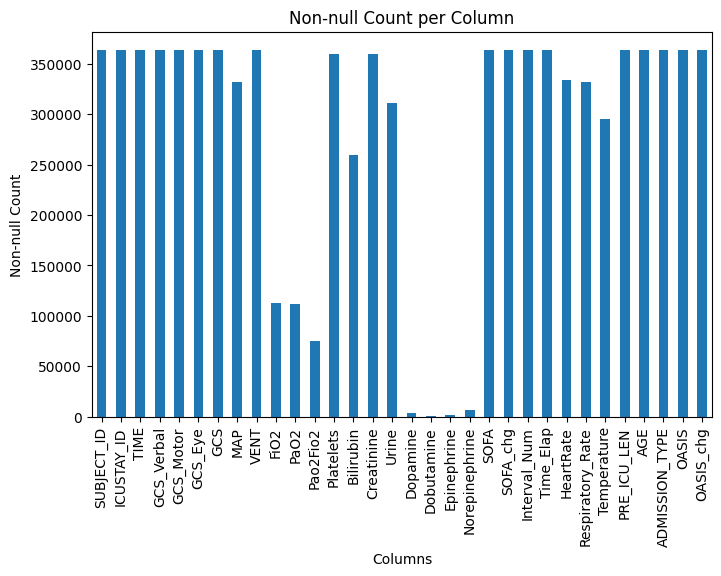

,0
SUBJECT_ID,363535
ICUSTAY_ID,363535
TIME,363535
GCS_Verbal,363535
GCS_Motor,363535
GCS_Eye,363535
GCS,363535
MAP,331383
VENT,363535
FiO2,112499


In [ ]:
import matplotlib.pyplot as plt

nonnull_counts = df.notnull().sum()

plt.figure(figsize=(8, 5))
nonnull_counts.plot(kind='bar')
plt.title("Non-null Count per Column")
plt.xlabel("Columns")
plt.ylabel("Non-null Count")
plt.show()
nonnull_counts

In [ ]:
print(df['SOFA'].describe())
print('\n', df['SOFA_chg'].describe())

count    363535.000000
mean          2.544080
std           2.564689
min           0.000000
25%           1.000000
50%           2.000000
75%           4.000000
max          23.000000
Name: SOFA, dtype: float64

 count    363535.000000
mean          0.037573
std           1.656533
min         -12.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          19.000000
Name: SOFA_chg, dtype: float64


In [ ]:
print(df['OASIS'].describe())
print('\n', df['OASIS_chg'].describe())

count    363535.000000
mean         24.771942
std           8.935548
min           0.000000
25%          18.000000
50%          24.000000
75%          31.000000
max          71.000000
Name: OASIS, dtype: float64

 count    363535.00000
mean          0.69338
std           6.96568
min         -34.00000
25%          -2.00000
50%           0.00000
75%           2.00000
max          47.00000
Name: OASIS_chg, dtype: float64
